# **01. Olist Dataset Loading and Initial Exploration (Customers)**
Initial exploration and data quality assessment of the Olist customers dataset.

In [1]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data_dir = Path("../data")
customers = pd.read_csv(data_dir / "olist_customers_dataset.csv")
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [3]:
print(customers.shape)
print("\n")
print(customers.info())

(99441, 5)


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB
None


In [4]:
customers.nunique()

customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64

In [5]:
customers["customer_unique_id"].value_counts()

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
ca77025e7201e3b30c44b472ff346268     7
                                    ..
1a29b476fee25c95fbafc67c5ac95cf8     1
d52a67c98be1cf6a5c84435bd38d095d     1
e9f50caf99f032f0bf3c55141f019d99     1
73c2643a0a458b49f58cea58833b192e     1
84732c5050c01db9b23e19ba39899398     1
Name: count, Length: 96096, dtype: int64

In [6]:
customers["customer_unique_id"].value_counts().value_counts().sort_index()

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

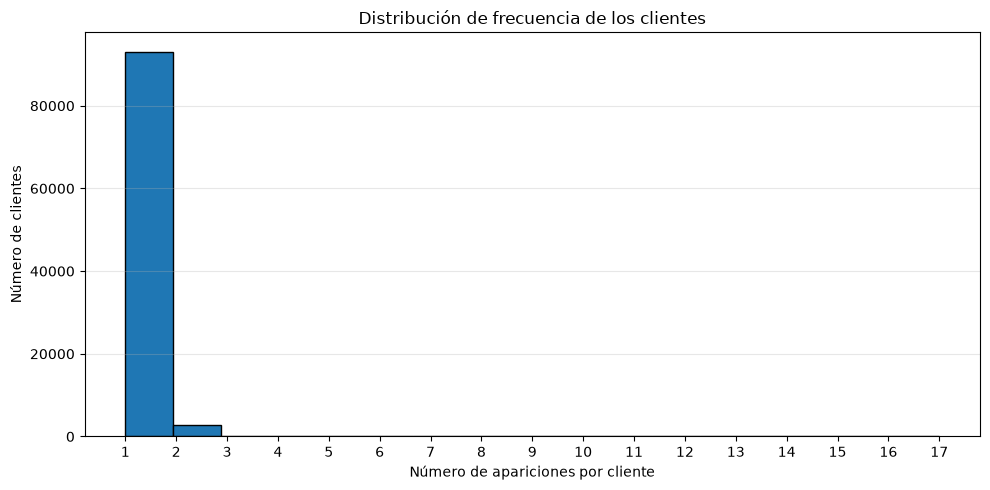

In [7]:
frecuencia_clientes = customers["customer_unique_id"].value_counts()

plt.figure(figsize=(10, 5))
plt.hist(frecuencia_clientes, bins=17, edgecolor="black")

plt.title("Distribución de frecuencia de los clientes")
plt.xlabel("Número de apariciones por cliente")
plt.ylabel("Número de clientes")
plt.xticks(range(1, 18))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
customers.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [9]:
# Comprobar registros duplicados
customers.duplicated().sum()

np.int64(0)

In [10]:
customers["customer_id"].is_unique

True

In [11]:
customers["customer_state"].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

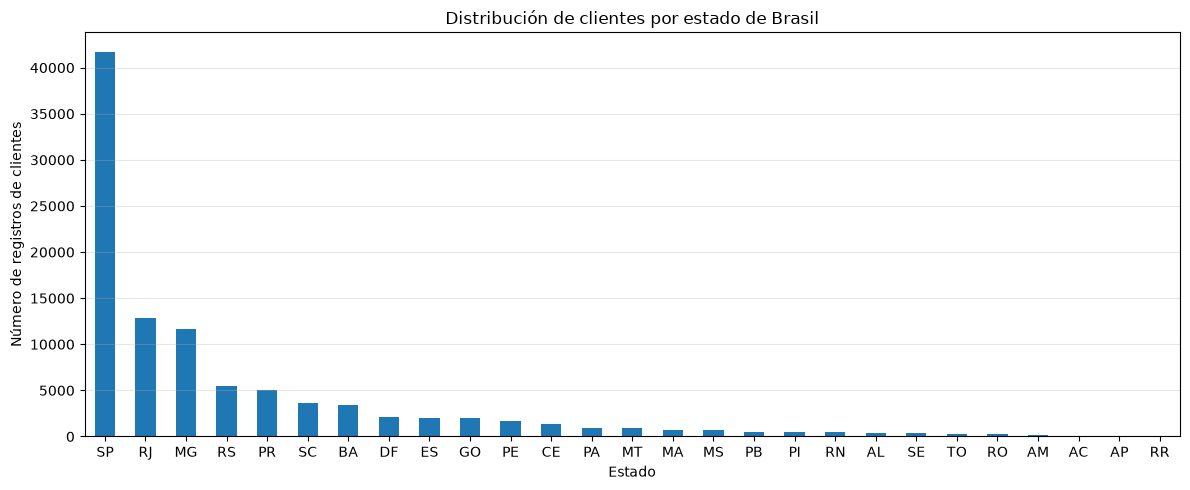

In [12]:
clientes_por_estado = customers["customer_state"].value_counts()

clientes_por_estado.plot(
    kind="bar",
    figsize=(12, 5),
    title="Distribución de clientes por estado de Brasil",
    xlabel="Estado",
    ylabel="Número de registros de clientes"
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
porcentaje_por_estado = (
    customers["customer_state"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

porcentaje_por_estado

customer_state
SP    41.98
RJ    12.92
MG    11.70
RS     5.50
PR     5.07
SC     3.66
BA     3.40
DF     2.15
ES     2.04
GO     2.03
PE     1.66
CE     1.34
PA     0.98
MT     0.91
MA     0.75
MS     0.72
PB     0.54
PI     0.50
RN     0.49
AL     0.42
SE     0.35
TO     0.28
RO     0.25
AM     0.15
AC     0.08
AP     0.07
RR     0.05
Name: proportion, dtype: float64

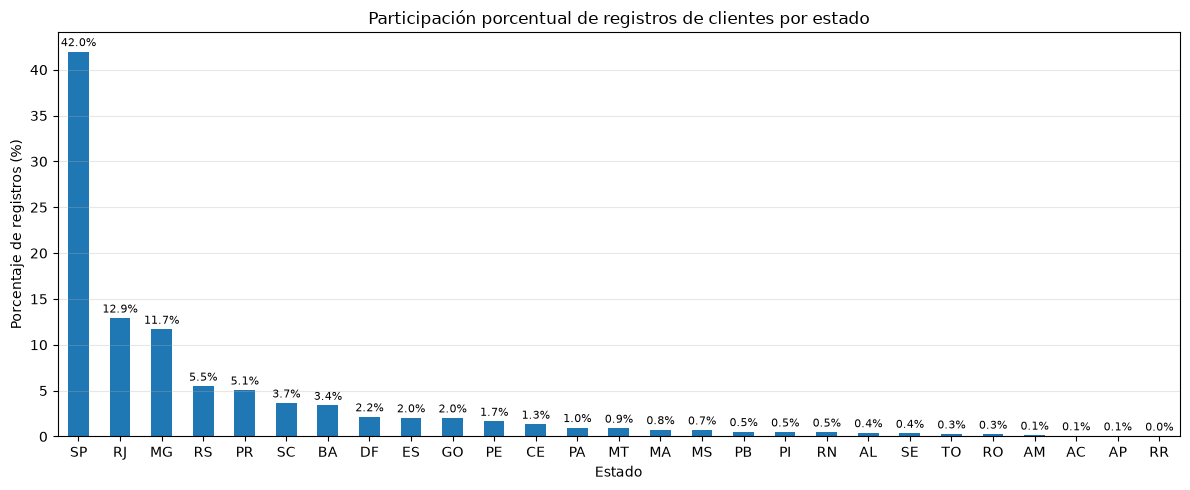

In [14]:
porcentaje_por_estado = (
    customers["customer_state"]
    .value_counts(normalize=True)
    .mul(100)
)

ax = porcentaje_por_estado.plot(
    kind="bar",
    figsize=(12, 5),
    title="Participación porcentual de registros de clientes por estado",
    xlabel="Estado",
    ylabel="Porcentaje de registros (%)"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=2,
    fontsize=8
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Geographic Distribution of Customer Records

The geographic distribution is highly concentrated in Brazil's southeastern states. São Paulo accounts for 42.0% of customer records, followed by Rio de Janeiro (12.9%) and Minas Gerais (11.7%). Together, these three states represent approximately 66.6% of all records in the dataset.

This concentration describes the distribution of customer records in the dataset; it does not necessarily represent the geographic distribution of Brazil's population or the number of distinct individuals.